# AI-Powered Paraphrasing Tool

This notebook builds a paraphrasing tool that rewrites a block of text with a **T5 transformer** (Hugging Face) and then **checks its own output** before returning it.

**Pipeline**

1. Split text into paragraphs and sentences (spaCy sentencizer).
2. T5 generates several candidate paraphrases per sentence (beam search + nucleus sampling).
3. Candidates are cleaned and scored on **meaning** (sentence-embedding similarity), **originality** (new word trigrams), **fluency** (GPT-2 perplexity), and **spelling/grammar** (built-in checks).
4. Candidates that change numbers or drift in meaning are rejected. The best remaining candidate is used. If none is safe, the original sentence is kept.
5. The tool is evaluated for accuracy (meaning preservation), originality, fluency and correctness using semantic similarity, BLEU, ROUGE, trigram novelty, perplexity and grammar-issue counts.

**Contents:** 1 Setup · 2 Metrics · 3 Grammar and spelling checks · 4 Paraphraser · 5 Sanity tests · 6 Load models · 7 Try it · 8 Evaluation · 9 Limitations

## 1. Libraries used

In [ ]:
import re, math, json, random, statistics as st
from dataclasses import dataclass, field, asdict
from typing import List, Optional

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

DEFAULT_MODEL = "humarin/chatgpt_paraphraser_on_T5_base"   # T5-base fine-tuned for paraphrasing
SEED = 42

## 2. Metrics and neural scorers

- **`ngram_novelty`**: share of the output's word trigrams that do not appear in the source (originality; 0 = copy).
- **`bleu` / `rouge`**: overlap metrics. Computed against the *source*, **lower means more original**. Against a human reference, higher means closer.
- **`SemanticSimilarity`**: cosine similarity of sentence embeddings (meaning preservation).
- **`FluencyScorer`**: DistilGPT-2 perplexity (lower = more fluent). A candidate as fluent as the source scores 1.0.

In [ ]:
# Text helpers
def tokenize(text: str) -> List[str]:
    """Lower-cased word tokens (letters, digits, apostrophes)."""
    return re.findall(r"[A-Za-z0-9']+", text.lower())


def _ngrams(tokens: List[str], n: int):
    return [tuple(tokens[i:i + n]) for i in range(len(tokens) - n + 1)]


def extract_numbers(text: str) -> List[str]:
    """Numbers such as 12, 3.5, 1,000. Used to make sure facts are not altered."""
    return [m.replace(",", "") for m in re.findall(r"\d[\d,]*\.?\d*", text)]


# Originality metrics (how different is the output from the source?)

def ngram_novelty(source: str, candidate: str, n: int = 3) -> float:
    """
    Fraction of the candidate's n-grams that do NOT appear in the source.
    0.0 = verbatim copy, 1.0 = no n-gram shared with the source.
    Falls back to smaller n for very short texts.
    """
    src, cand = tokenize(source), tokenize(candidate)
    while n > 1 and len(cand) < n:
        n -= 1
    cand_ng = _ngrams(cand, n)
    if not cand_ng:
        return 0.0
    src_ng = set(_ngrams(src, n))
    return sum(g not in src_ng for g in cand_ng) / len(cand_ng)


def bleu(reference: str, hypothesis: str) -> float:
    """Sentence BLEU (0..1) with smoothing. Against the SOURCE, lower = more original."""
    from nltk.translate.bleu_score import SmoothingFunction, sentence_bleu
    ref, hyp = tokenize(reference), tokenize(hypothesis)
    if not ref or not hyp:
        return 0.0
    return float(sentence_bleu([ref], hyp, smoothing_function=SmoothingFunction().method1))


def rouge(reference: str, hypothesis: str) -> dict:
    """ROUGE-1 and ROUGE-L F1 scores (0..1)."""
    from rouge_score import rouge_scorer
    scorer = rouge_scorer.RougeScorer(["rouge1", "rougeL"], use_stemmer=True)
    s = scorer.score(reference, hypothesis)
    return {"rouge1": s["rouge1"].fmeasure, "rougeL": s["rougeL"].fmeasure}

# Neural scorers

class SemanticSimilarity:
    """Cosine similarity between sentence embeddings (1.0 = identical meaning)."""

    def __init__(self, model_name: str = "sentence-transformers/all-MiniLM-L6-v2"):
        from sentence_transformers import SentenceTransformer
        self.model = SentenceTransformer(model_name)

    def score(self, a: str, b: str) -> float:
        from sentence_transformers import util
        emb = self.model.encode([a, b], convert_to_tensor=True, normalize_embeddings=True)
        return float(util.cos_sim(emb[0], emb[1]))


class FluencyScorer:
    """
    Language-model perplexity (lower = more fluent / natural).
    We compare a candidate's perplexity to the source's: a paraphrase that is
    as fluent as the original gets a score of 1.0.
    """

    def __init__(self, model_name: str = "distilgpt2", device: Optional[str] = None):
        import torch
        from transformers import AutoModelForCausalLM, AutoTokenizer
        self.torch = torch
        self.device = device or ("cuda" if torch.cuda.is_available() else "cpu")
        self.tokenizer = AutoTokenizer.from_pretrained(model_name)
        self.model = AutoModelForCausalLM.from_pretrained(model_name).to(self.device).eval()

    def perplexity(self, text: str) -> float:
        # Prepend BOS so the first real token is also scored.
        ids = self.tokenizer(self.tokenizer.bos_token + text, return_tensors="pt",
                             truncation=True, max_length=512).input_ids.to(self.device)
        with self.torch.no_grad():
            loss = self.model(ids, labels=ids).loss
        return float(math.exp(loss.item()))

    def score(self, source: str, candidate: str) -> float:
        """Relative fluency in [0, 1]: min(1, ppl(source) / ppl(candidate))."""
        ps, pc = self.perplexity(source), self.perplexity(candidate)
        return max(0.0, min(1.0, ps / pc)) if pc > 0 else 0.0

## 3. Grammar, spelling and style checks

Three layers: (1) spelling with an offline dictionary (words from the source, acronyms and proper nouns are ignored), (2) rule checks (repeated words, capitalisation, final punctuation, brackets/quotes, spacing, a/an), and (3) optional LanguageTool (needs Java). `fix()` applies only safe corrections that never change meaning.

In [ ]:
class GrammarChecker:
    # Words that can legitimately be doubled ("he had had enough", "said that that was").
    VALID_REPEATS = {"had", "that"}

    def __init__(self, use_languagetool: bool = False):
        from spellchecker import SpellChecker
        self.spell = SpellChecker()
        self.lt = None
        if use_languagetool:
            try:
                import language_tool_python
                self.lt = language_tool_python.LanguageTool("en-US")
            except Exception as exc:  # Java missing, offline, etc.
                print(f"[grammar] LanguageTool unavailable ({exc}); using built-in rules only.")

    # Checking

    def check(self, text: str, source: str = "") -> List[str]:
        """Return a list of human-readable issues found in `text`."""
        issues: List[str] = []
        known = set(re.findall(r"[A-Za-z']+", source.lower()))

        # 1. Spelling
        words = re.findall(r"[A-Za-z']+", text)
        for i, w in enumerate(words):
            lw = w.lower().strip("'")
            if len(lw) < 3 or lw in known or w.isupper():
                continue
            if w[0].isupper() and i > 0:      # likely a proper noun
                continue
            if lw in self.spell.unknown([lw]):
                issues.append(f"spelling: '{w}'")

        # 2. Rule-based checks
        for m in re.finditer(r"\b(\w+)\s+\1\b", text, flags=re.I):
            if m.group(1).lower() not in self.VALID_REPEATS:
                issues.append(f"repeated word: '{m.group(1)}'")
        stripped = text.strip()
        if stripped and stripped[0].isalpha() and not stripped[0].isupper():
            issues.append("sentence does not start with a capital letter")
        if stripped and stripped[-1] not in ".!?\"')":
            issues.append("missing final punctuation")
        if text.count("(") != text.count(")"):
            issues.append("unbalanced parentheses")
        if text.count('"') % 2:
            issues.append("unbalanced quotation marks")
        if re.search(r"\s{2,}|\s+[,.;:!?]", text):
            issues.append("spacing problem")
        for m in re.finditer(r"\b(a|an)\s+([A-Za-z]+)", text, flags=re.I):
            art, nxt = m.group(1).lower(), m.group(2).lower()
            if art == "a" and nxt[0] in "aeio" and not nxt.startswith(("one", "once")):
                issues.append(f"article: 'a {nxt}' should probably be 'an {nxt}'")

        # 3. Optional LanguageTool
        if self.lt is not None:
            for match in self.lt.check(text):
                if match.ruleId not in ("MORFOLOGIK_RULE_EN_US",):   # spelling already handled
                    issues.append(f"grammar: {match.message}")
        return issues

    # Safe automatic fixes (never changes meaning

    def fix(self, text: str) -> str:
        text = re.sub(r"\s+", " ", text).strip()
        text = re.sub(r"\s+([,.;:!?])", r"\1", text)                   # space before punctuation
        text = re.sub(r"\b(\w+)(\s+\1\b)+",                          # repeated words
                      lambda m: m.group(0) if m.group(1).lower() in self.VALID_REPEATS
                      else m.group(1), text, flags=re.I)
        text = re.sub(r"\b[Aa] ([aeio]\w*)",
                      lambda m: ("An " if m.group(0)[0] == "A" else "an ") + m.group(1)
                      if not m.group(1).lower().startswith(("one", "once")) else m.group(0), text)
        if text and text[0].isalpha():
            text = text[0].upper() + text[1:]
        if text and text[-1] not in ".!?\"')":
            text += "."
        return text

## 4. The paraphraser

`T5Generator` produces candidates. `Paraphraser` cleans, filters, scores and selects them.

Ranking weights: **0.40 meaning + 0.20 originality + 0.25 fluency + 0.15 grammar**. Hard rules: numbers must be unchanged and similarity must be at least `min_similarity` (default 0.80). Otherwise the original sentence is kept.

In [ ]:
# Data containers

@dataclass
class SentenceResult:
    original: str
    paraphrase: str
    similarity: float = 1.0
    originality: float = 0.0
    fluency: float = 1.0
    grammar_issues: List[str] = field(default_factory=list)
    candidates_considered: int = 0
    used_fallback: bool = False       # True -> original sentence kept
    note: str = ""


@dataclass
class ParaphraseResult:
    original_text: str
    paraphrased_text: str
    sentences: List[SentenceResult]
    summary: dict


# Candidate generation (T5)

class T5Generator:
    """Generates paraphrase candidates with a Hugging Face seq2seq model."""

    def __init__(self, model_name: str = DEFAULT_MODEL, device: Optional[str] = None):
        import torch
        from transformers import AutoModelForSeq2SeqLM, AutoTokenizer
        self.torch = torch
        self.device = device or ("cuda" if torch.cuda.is_available() else "cpu")
        self.tokenizer = AutoTokenizer.from_pretrained(model_name)
        self.model = AutoModelForSeq2SeqLM.from_pretrained(model_name).to(self.device).eval()

    def generate(self, sentence: str, n: int = 5) -> List[str]:
        enc = self.tokenizer(f"paraphrase: {sentence}", return_tensors="pt",
                             truncation=True, max_length=256).to(self.device)
        max_new = int(enc.input_ids.shape[1] * 1.6) + 10
        outs: List[str] = []
        with self.torch.no_grad():
            # (a) beam search: high-quality but conservative candidates
            beams = self.model.generate(**enc, num_beams=max(4, n), num_return_sequences=min(2, n),
                                        no_repeat_ngram_size=3, max_new_tokens=max_new)
            # (b) nucleus sampling: more diverse / original candidates
            samples = self.model.generate(**enc, do_sample=True, top_p=0.92, top_k=50,
                                          temperature=1.0, num_return_sequences=n,
                                          no_repeat_ngram_size=3, max_new_tokens=max_new)
        for seq in list(beams) + list(samples):
            outs.append(self.tokenizer.decode(seq, skip_special_tokens=True).strip())
        return outs



# Main class

class Paraphraser:
    def __init__(self, generator, similarity, fluency, grammar: Optional[GrammarChecker] = None,
                 num_candidates: int = 5, min_similarity: float = 0.80,
                 min_originality: float = 0.30,
                 weights=(0.40, 0.20, 0.25, 0.15)):
        """
        generator       : object with .generate(sentence, n) -> list[str]
        similarity      : object with .score(a, b) -> float in [0, 1]
        fluency         : object with .score(source, candidate) -> float in [0, 1]
        weights         : (meaning, originality, fluency, grammar) used for ranking
        min_similarity  : candidates below this are rejected (meaning drift)
        min_originality : candidates below this are flagged as "too close to source"
        """
        self.generator, self.similarity, self.fluency = generator, similarity, fluency
        self.grammar = grammar or GrammarChecker()
        self.num_candidates = num_candidates
        self.min_similarity, self.min_originality = min_similarity, min_originality
        self.weights = weights
        # Rule-based sentence splitter: no model download needed.
        import spacy
        self.nlp = spacy.blank("en")
        self.nlp.add_pipe("sentencizer")

    @classmethod
    def default(cls, model_name: str = DEFAULT_MODEL, use_languagetool: bool = False, **kwargs):
        """Build the full pipeline with the default Hugging Face models."""
        return cls(T5Generator(model_name), SemanticSimilarity(), FluencyScorer(),
                   GrammarChecker(use_languagetool), **kwargs)

    # ------------------------------------------------------------------ #
    def split_sentences(self, paragraph: str) -> List[str]:
        return [s.text.strip() for s in self.nlp(paragraph).sents if s.text.strip()]

    @staticmethod
    def _norm(s: str) -> str:
        return re.sub(r"\W+", " ", s.lower()).strip()

    # ------------------------------------------------------------------ #
    def paraphrase_sentence(self, sentence: str) -> SentenceResult:
        raw = self.generator.generate(sentence, self.num_candidates)

        # Clean + de-duplicate; drop candidates identical to the source.
        seen, cands = {self._norm(sentence)}, []
        for c in raw:
            c = self.grammar.fix(c)
            if c and self._norm(c) not in seen:
                seen.add(self._norm(c))
                cands.append(c)

        w_sim, w_org, w_flu, w_gram = self.weights
        src_numbers = sorted(extract_numbers(sentence))
        best, best_score, rejected = None, -1.0, 0
        for c in cands:
            if sorted(extract_numbers(c)) != src_numbers:          # facts must not change
                rejected += 1
                continue
            sim = self.similarity.score(sentence, c)
            if sim < self.min_similarity:                          # meaning drift
                rejected += 1
                continue
            org = ngram_novelty(sentence, c)
            flu = self.fluency.score(sentence, c)
            issues = self.grammar.check(c, source=sentence)
            score = w_sim * sim + w_org * org + w_flu * flu + w_gram / (1 + len(issues))
            if score > best_score:
                best_score = score
                best = SentenceResult(sentence, c, sim, org, flu, issues, len(cands))

        if best is None:   # nothing safe -> keep the original sentence
            return SentenceResult(sentence, sentence, 1.0, 0.0, 1.0, [], len(cands), True,
                                  f"no candidate met the quality bar ({rejected}/{len(cands)} rejected)")
        if best.originality < self.min_originality:
            best.note = "low originality (close to source wording)"
        return best

    def paraphrase(self, text: str) -> ParaphraseResult:
        paragraphs, results = [], []
        for para in re.split(r"\n\s*\n", text.strip()):
            sents = [self.paraphrase_sentence(s) for s in self.split_sentences(para)]
            results.extend(sents)
            paragraphs.append(" ".join(s.paraphrase for s in sents))
        out = "\n\n".join(paragraphs)
        return ParaphraseResult(text, out, results, self._summary(text, out, results))

    def _summary(self, src: str, out: str, sents: List[SentenceResult]) -> dict:
        n = max(len(sents), 1)
        return {
            "sentences": len(sents),
            "kept_original": sum(s.used_fallback for s in sents),
            "mean_similarity": sum(s.similarity for s in sents) / n,
            "mean_originality": sum(s.originality for s in sents) / n,
            "mean_fluency": sum(s.fluency for s in sents) / n,
            "grammar_issues": sum(len(s.grammar_issues) for s in sents),
            "overall_similarity": self.similarity.score(src, out),
            "overall_originality": ngram_novelty(src, out),
        }

## 5. Sanity tests (no model download needed)

These tests replace the neural models with tiny fakes to verify the logic around them: number protection, meaning threshold, fallback, reranking, paragraph structure, and grammar checks.

In [ ]:
class _FakeGen:
    def __init__(self, c): self.c = c
    def generate(self, s, n=5): return list(self.c)
class _FakeSim:                                   # word-overlap stand-in for embeddings
    def score(self, a, b):
        A, B = set(tokenize(a)), set(tokenize(b)); return len(A & B) / max(len(A | B), 1)
class _FakeFlu:
    def score(self, s, c): return 1.0

def _make(cands, **kw):
    return Paraphraser(_FakeGen(cands), _FakeSim(), _FakeFlu(), GrammarChecker(),
                       min_similarity=kw.pop("min_similarity", 0.3), **kw)

SRC = "The company reported 120 new customers in the quarter."

# 1. changed numbers are rejected -> original kept
r = _make(["The firm reported 150 new customers during the quarter."]).paraphrase_sentence(SRC)
assert r.used_fallback and r.paraphrase == SRC
# 2. meaning drift is rejected
assert _make(["Bananas are yellow and grow in warm places."], min_similarity=0.5).paraphrase_sentence(SRC).used_fallback
# 3. a good candidate is accepted and its grammar fixed
r = _make(["the company  gained 120 new customers in the quarter"]).paraphrase_sentence(SRC)
assert r.paraphrase == "The company gained 120 new customers in the quarter."
# 4. identical output is dropped
assert _make([SRC]).paraphrase_sentence(SRC).used_fallback
# 5. originality weight changes the winner
cands = ["The company reported 120 new customers in the quarter now.", "The firm gained 120 new customers over the quarter."]
assert _make(cands).paraphrase_sentence(SRC).paraphrase.startswith("The company reported")
assert _make(cands, weights=(0.1, 0.8, 0.05, 0.05)).paraphrase_sentence(SRC).paraphrase.startswith("The firm gained")
# 6. paragraph structure preserved
res = _make(["The firm gained 120 new customers over the quarter."]).paraphrase(SRC + " " + SRC + "\n\n" + SRC)
assert res.paraphrased_text.count("\n\n") == 1 and res.summary["sentences"] == 3
# 7. grammar / spelling checks
g = GrammarChecker()
issues = " | ".join(g.check("the the cat sat on a apple", source="cat apple"))
assert "capital" in issues and "repeated" in issues and "final punctuation" in issues and "article" in issues
assert any("spelling" in i for i in g.check("This is a recieved message.", source=""))
assert not any("spelling" in i for i in g.check("Zorblax went home.", source="Zorblax"))
assert "had had" in g.fix("He had had enough.")
# 8. metrics
assert extract_numbers("It cost 1,200 or 3.5 dollars") == ["1200", "3.5"]
assert ngram_novelty("a b c d e", "a b c d e") == 0.0 and ngram_novelty("a b c d e", "v w x y z") == 1.0
assert bleu("the cat sat on the mat", "the cat sat on the mat") > 0.9
assert rouge("the cat sat", "the cat sat")["rougeL"] == 1.0
print("All sanity tests passed.")

All sanity tests passed.


## 6. Load the models
Downloads T5, MiniLM and DistilGPT-2 on first run (about 1 GB).

In [ ]:
from transformers import set_seed
set_seed(SEED)
tool = Paraphraser.default(num_candidates=5, min_similarity=0.80)
print("Models loaded. Device:", tool.generator.device)

Loading weights:   0%|          | 0/257 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/76 [00:00<?, ?it/s]

Models loaded. Device: cuda


## 7. Try it

Edit `text` and re-run. The output includes per-sentence scores so you can see why each sentence was chosen (or kept unchanged).

In [ ]:
text = """Regular exercise has been shown to reduce the risk of heart disease, improve mood, and help people sleep better at night. Adults are advised to get at least 150 minutes of moderate activity every week. Even short walks can make a noticeable difference."""

result = tool.paraphrase(text)

print("ORIGINAL:\n" + result.original_text)
print("\nPARAPHRASE:\n" + result.paraphrased_text)

display(pd.DataFrame([{
    "original": s.original, "paraphrase": s.paraphrase,
    "similarity": round(s.similarity, 2), "originality": round(s.originality, 2),
    "fluency": round(s.fluency, 2), "grammar issues": len(s.grammar_issues),
    "kept original": s.used_fallback, "note": s.note} for s in result.sentences]))
print("\nSUMMARY:", {k: round(v, 3) if isinstance(v, float) else v for k, v in result.summary.items()})

ORIGINAL:
Regular exercise has been shown to reduce the risk of heart disease, improve mood, and help people sleep better at night. Adults are advised to get at least 150 minutes of moderate activity every week. Even short walks can make a noticeable difference.

PARAPHRASE:
People who engage in regular exercise may experience a decrease in their risk of heart disease, an improvement in their mood, and a better night's sleep. Adults are required to engage in moderate physical activity for a minimum of 150 minutes per week. It does seem like a small difference from a short walk.


,original,paraphrase,similarity,originality,fluency,grammar issues,kept original,note
0,Regular exercise has been shown to reduce the ...,People who engage in regular exercise may expe...,0.88,0.92,1.0,0,False,
1,Adults are advised to get at least 150 minutes...,Adults are required to engage in moderate phys...,0.89,1.00,1.0,0,False,
2,Even short walks can make a noticeable differe...,It does seem like a small difference from a sh...,0.81,1.00,1.0,0,False,



SUMMARY: {'sentences': 3, 'kept_original': 0, 'mean_similarity': 0.861, 'mean_originality': 0.972, 'mean_fluency': 1.0, 'grammar_issues': 0, 'overall_similarity': 0.916, 'overall_originality': 0.962}


## 8. Evaluation

Five sample paragraphs (different domains) are paraphrased and the output of the tool is scored on:

- **Accuracy (meaning preservation):** semantic similarity to the source, and the share of paragraphs at or above 0.80. Numbers must also be unchanged.
- **Originality:** trigram novelty (higher = more new wording) and BLEU / ROUGE-L against the source (lower = less copying).
- **Fluency:** perplexity of the output. The human-written source text is shown alongside as a reference level.
- **Correctness:** spelling and grammar issues per 100 words.

In [ ]:
SAMPLES = [
    "Regular exercise has been shown to reduce the risk of heart disease, improve mood, and help people sleep better at night. Adults are advised to get at least 150 minutes of moderate activity every week. Even short walks can make a noticeable difference.",
    "The city council approved a new budget of 4.2 million dollars for repairing roads and bridges. Work is expected to begin in March and finish before the end of the year. Residents may experience delays on some of the busiest routes during construction.",
    "Machine learning models learn patterns from large amounts of data instead of following explicitly programmed rules. Once trained, they can make predictions about new examples they have never seen before. However, their performance depends heavily on the quality and diversity of the training data.",
    "Climate change is causing sea levels to rise, which threatens coastal communities around the world. Scientists estimate that global sea levels could increase by up to one meter by the end of the century. Governments are being urged to invest in flood defenses and to cut greenhouse gas emissions.",
    "Our new mobile application makes it easy to track your daily expenses and set monthly savings goals. Users can scan receipts, categorize purchases automatically, and receive alerts when they are close to exceeding their budget. The app is free to download and works on both Android and iOS devices.",
]
# Optional: human reference paraphrases (same order) for BLEU/ROUGE vs reference, e.g. REFERENCES = ["...", ...]
REFERENCES = None
THRESHOLD = 0.80

set_seed(SEED)
rows, src_rows, outputs = [], [], []
for i, src in enumerate(SAMPLES):
    res = tool.paraphrase(src)
    out = res.paraphrased_text
    n_words = max(len(tokenize(out)), 1)
    sim = tool.similarity.score(src, out)
    row = {
        "similarity": sim,
        "meaning_preserved": float(sim >= THRESHOLD),
        "novelty_3gram": ngram_novelty(src, out),
        "bleu_vs_source": bleu(src, out),
        "rougeL_vs_source": rouge(src, out)["rougeL"],
        "perplexity": tool.fluency.perplexity(out),
        "issues_per_100w": 100 * len(tool.grammar.check(out, source=src)) / n_words,
        "kept_original_pct": 100 * res.summary["kept_original"] / max(res.summary["sentences"], 1),
    }
    if REFERENCES:
        row["bleu_vs_ref"], row["rougeL_vs_ref"] = bleu(REFERENCES[i], out), rouge(REFERENCES[i], out)["rougeL"]
    rows.append(row)
    src_rows.append({"perplexity": tool.fluency.perplexity(src),
                     "issues_per_100w": 100 * len(tool.grammar.check(src)) / max(len(tokenize(src)), 1)})
    outputs.append((src, res))

per_paragraph = pd.DataFrame(rows, index=[f"Paragraph {i}" for i in range(1, len(rows) + 1)])
display(per_paragraph.round(3))

labels = {"similarity": "Semantic similarity to source (higher = meaning kept)",
          "meaning_preserved": "Meaning preserved (% of paragraphs)",
          "novelty_3gram": "Trigram novelty (higher = more original)",
          "bleu_vs_source": "BLEU vs source (LOWER = more original)",
          "rougeL_vs_source": "ROUGE-L vs source (LOWER = more original)",
          "perplexity": "Perplexity (lower = more fluent)",
          "issues_per_100w": "Spelling/grammar issues per 100 words (lower = better)",
          "kept_original_pct": "Sentences kept unchanged (no safe candidate, %)"}
if REFERENCES:
    labels.update({"bleu_vs_ref": "BLEU vs human reference (higher = closer)",
                   "rougeL_vs_ref": "ROUGE-L vs human reference (higher = closer)"})

mean = lambda rs, k: st.mean(r[k] for r in rs)
summary_table = pd.DataFrame(
    [{"Metric": text_, "Source text": mean(src_rows, k) if k in src_rows[0] else None,
      "Tool output (average)": mean(rows, k)} for k, text_ in labels.items()]).set_index("Metric")
summary_table.loc["Meaning preserved (% of paragraphs)", "Tool output (average)"] *= 100
display(summary_table.round(3))

,similarity,meaning_preserved,novelty_3gram,bleu_vs_source,rougeL_vs_source,perplexity,issues_per_100w,kept_original_pct
Paragraph 1,0.916,1.0,0.962,0.081,0.388,19.707,0.0,0.0
Paragraph 2,0.962,1.0,0.680,0.387,0.625,18.367,0.0,0.0
Paragraph 3,0.859,1.0,0.792,0.283,0.574,28.845,0.0,0.0
Paragraph 4,0.950,1.0,0.804,0.278,0.549,16.124,0.0,0.0
Paragraph 5,0.923,1.0,0.904,0.146,0.505,32.236,0.0,0.0


,Source text,Tool output (average)
Metric,,
Semantic similarity to source (higher = meaning kept),NaN,0.922
Meaning preserved (% of paragraphs),NaN,100.000
Trigram novelty (higher = more original),NaN,0.828
BLEU vs source (LOWER = more original),NaN,0.235
ROUGE-L vs source (LOWER = more original),NaN,0.528
Perplexity (lower = more fluent),20.952,23.056
Spelling/grammar issues per 100 words (lower = better),0.816,0.000
"Sentences kept unchanged (no safe candidate, %)",NaN,0.000


In [ ]:
# Sample outputs: original vs paraphrased
for i, (src, res) in enumerate(outputs, 1):
    display(Markdown(f"### Example {i}\n**Original**\n\n{src}\n\n**Paraphrase**\n\n{res.paraphrased_text}"))

### Example 1
**Original**

Regular exercise has been shown to reduce the risk of heart disease, improve mood, and help people sleep better at night. Adults are advised to get at least 150 minutes of moderate activity every week. Even short walks can make a noticeable difference.

**Paraphrase**

People who engage in regular exercise may experience a decrease in their risk of heart disease, an improvement in their mood, and a better night's sleep. Adults are required to engage in moderate physical activity for a minimum of 150 minutes per week. It does seem like a small difference from a short walk.

### Example 2
**Original**

The city council approved a new budget of 4.2 million dollars for repairing roads and bridges. Work is expected to begin in March and finish before the end of the year. Residents may experience delays on some of the busiest routes during construction.

**Paraphrase**

A new budget of 4.2 million dollars was approved by the city council for the purpose of repairing roads and bridges. The work is planned to start in March and be finished by the end of the year. During construction, some of the busiest routes may result in delays for residents.

### Example 3
**Original**

Machine learning models learn patterns from large amounts of data instead of following explicitly programmed rules. Once trained, they can make predictions about new examples they have never seen before. However, their performance depends heavily on the quality and diversity of the training data.

**Paraphrase**

Patterns are automatically learned by machine learning models from large quantities of data, rather than being programmed to perform specific tasks. They can predict new examples in a way they have never seen before during their training. The quality and diversity of the training data are crucial to their performance.

### Example 4
**Original**

Climate change is causing sea levels to rise, which threatens coastal communities around the world. Scientists estimate that global sea levels could increase by up to one meter by the end of the century. Governments are being urged to invest in flood defenses and to cut greenhouse gas emissions.

**Paraphrase**

Sea levels are set to rise due to climate change, putting coastal communities at risk. Global sea levels have the potential to increase by as much as one meter by the end of the century, according to scientists. Investment in flood defenses and reduction of greenhouse gas emissions is being demanded by governments.

### Example 5
**Original**

Our new mobile application makes it easy to track your daily expenses and set monthly savings goals. Users can scan receipts, categorize purchases automatically, and receive alerts when they are close to exceeding their budget. The app is free to download and works on both Android and iOS devices.

**Paraphrase**

Our new mobile application provides the opportunity to monitor your daily spending and establish monthly savings goals in the comfort of your own home. By scanning receipts, users can sort purchases, receive notifications, and print receipts that are just inches above their budget. This app is available for free on Android and iOS devices.

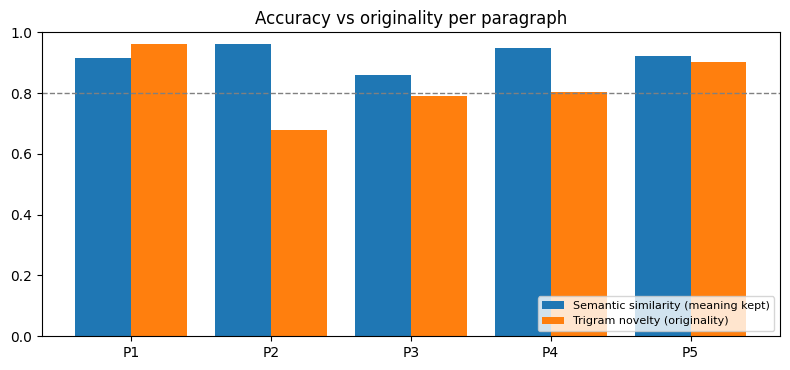

Saved evaluation_results.csv and sample_results.md


In [ ]:
# Chart: meaning kept versu originality for each paragraph
x = range(len(rows))
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.bar([i - 0.2 for i in x], per_paragraph["similarity"], width=0.4, label="Semantic similarity (meaning kept)")
ax.bar([i + 0.2 for i in x], per_paragraph["novelty_3gram"], width=0.4, label="Trigram novelty (originality)")
ax.set_xticks(list(x)); ax.set_xticklabels([f"P{i+1}" for i in x]); ax.set_ylim(0, 1)
ax.axhline(THRESHOLD, color="gray", linestyle="--", linewidth=1)
ax.set_title("Accuracy vs originality per paragraph"); ax.legend(loc="lower right", fontsize=8)
plt.tight_layout(); plt.show()

# Save results to files
summary_table.round(4).to_csv("evaluation_results.csv")
with open("sample_results.md", "w", encoding="utf-8") as f:
    for i, (src, res) in enumerate(outputs, 1):
        f.write(f"## Example {i}\n\n**Original**\n\n{src}\n\n**Paraphrase**\n\n{res.paraphrased_text}\n\n")
print("Saved evaluation_results.csv and sample_results.md")

### How to read the results

- **Accuracy:** semantic similarity close to or above the dashed 0.80 line means the meaning was kept. Numbers never change because the tool rejects any candidate that alters them.
- **Originality:** high trigram novelty and low BLEU / ROUGE-L against the source mean the wording was really changed. Meaning and originality trade off: a perfect copy scores 1.0 similarity and 0.0 novelty.
- **Fluency and correctness:** perplexity near the source level and few issues per 100 words mean the output reads naturally.
- **Kept unchanged:** the share of sentences left alone because no candidate was safe.